In [1]:
# EDP - Week 8
# Project: Resume-to-Job Matching Platform

print("Week 8: Resume-to-Job Matching Platform")
print("Topic: Improving and Comparing Resume Matching Algorithms")

Week 8: Resume-to-Job Matching Platform
Topic: Improving and Comparing Resume Matching Algorithms


In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [3]:
data_path = os.path.join(
    "Resume_Job_Matching",
    "data",
    "data",
    "all_resumes.csv"
)

df = pd.read_csv(data_path)

df["resume_text"] = df["resume_text"].fillna("").astype(str)
df = df[df["resume_text"].str.strip() != ""].copy()
df.reset_index(drop=True, inplace=True)

print("Dataset loaded successfully!")
print("Usable resumes:", len(df))
print("Columns:", df.columns.tolist())

df.head()

Dataset loaded successfully!
Usable resumes: 2483
Columns: ['filename', 'category', 'resume_text']


,filename,category,resume_text
0,10554236.pdf,ACCOUNTANT,ACCOUNTANT\nSummary\nFinancial Accountant spec...
1,10674770.pdf,ACCOUNTANT,STAFF ACCOUNTANT\nSummary\nHighly analytical a...
2,11163645.pdf,ACCOUNTANT,ACCOUNTANT\nProfessional Summary\nTo obtain a ...
3,11759079.pdf,ACCOUNTANT,SENIOR ACCOUNTANT\nExperience\nCompany Name\n ...
4,12065211.pdf,ACCOUNTANT,SENIOR ACCOUNTANT\nProfessional Summary\nSenio...


In [4]:
vectorizer_basic = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 1)
)

resume_vectors_basic = vectorizer_basic.fit_transform(
    df["resume_text"]
)

print("Basic TF-IDF model created!")
print("Vector matrix shape:", resume_vectors_basic.shape)

Basic TF-IDF model created!
Vector matrix shape: (2483, 10000)


In [5]:
vectorizer_improved = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

resume_vectors_improved = vectorizer_improved.fit_transform(
    df["resume_text"]
)

print("Improved TF-IDF model created!")
print("Vector matrix shape:", resume_vectors_improved.shape)

Improved TF-IDF model created!
Vector matrix shape: (2483, 10000)


In [6]:
job_description = """
We are looking for a Data Analyst with experience in Python,
SQL, Pandas, NumPy, data analysis, and data visualization.
The candidate should analyze datasets, identify trends,
prepare reports, and communicate insights.
"""

job_vector_basic = vectorizer_basic.transform([job_description])
job_vector_improved = vectorizer_improved.transform([job_description])

scores_basic = cosine_similarity(
    job_vector_basic,
    resume_vectors_basic
).flatten()

scores_improved = cosine_similarity(
    job_vector_improved,
    resume_vectors_improved
).flatten()

top_basic = np.argsort(scores_basic)[::-1][:5]
top_improved = np.argsort(scores_improved)[::-1][:5]

print("BASIC TF-IDF — TOP 5")
display(
    pd.DataFrame({
        "filename": df.iloc[top_basic]["filename"].values,
        "category": df.iloc[top_basic]["category"].values,
        "similarity_percentage": np.round(
            scores_basic[top_basic] * 100, 2
        )
    })
)

print("IMPROVED TF-IDF — TOP 5")
display(
    pd.DataFrame({
        "filename": df.iloc[top_improved]["filename"].values,
        "category": df.iloc[top_improved]["category"].values,
        "similarity_percentage": np.round(
            scores_improved[top_improved] * 100, 2
        )
    })
)

BASIC TF-IDF — TOP 5


,filename,category,similarity_percentage
0,21156767.pdf,CONSULTANT,34.17
1,62994611.pdf,AGRICULTURE,28.56
2,42156237.pdf,DIGITAL-MEDIA,26.47
3,18448085.pdf,AUTOMOBILE,26.10
4,12011623.pdf,ENGINEERING,25.12


IMPROVED TF-IDF — TOP 5


,filename,category,similarity_percentage
0,18448085.pdf,AUTOMOBILE,24.73
1,42156237.pdf,DIGITAL-MEDIA,22.15
2,12011623.pdf,ENGINEERING,19.67
3,21156767.pdf,CONSULTANT,17.83
4,25397102.pdf,BUSINESS-DEVELOPMENT,13.32


In [7]:
basic_top10 = np.argsort(scores_basic)[::-1][:10]
improved_top10 = np.argsort(scores_improved)[::-1][:10]

basic_results = pd.DataFrame({
    "filename": df.iloc[basic_top10]["filename"].values,
    "basic_score": np.round(scores_basic[basic_top10] * 100, 2)
})

improved_results = pd.DataFrame({
    "filename": df.iloc[improved_top10]["filename"].values,
    "improved_score": np.round(scores_improved[improved_top10] * 100, 2)
})

model_comparison = basic_results.merge(
    improved_results,
    on="filename",
    how="outer"
)

model_comparison

,filename,basic_score,improved_score
0,10265057.pdf,NaN,11.43
1,12011623.pdf,25.12,19.67
2,18067556.pdf,17.01,NaN
3,18448085.pdf,26.10,24.73
4,21156767.pdf,34.17,17.83
5,22232367.pdf,NaN,11.82
6,24610685.pdf,19.87,NaN
7,25397102.pdf,17.22,13.32
8,26585242.pdf,17.95,11.72
9,28998957.pdf,NaN,11.97


In [8]:
basic_names = set(df.iloc[basic_top10]["filename"])
improved_names = set(df.iloc[improved_top10]["filename"])

common_resumes = basic_names.intersection(improved_names)

print("Basic model top 10:", len(basic_names))
print("Improved model top 10:", len(improved_names))
print("Resumes appearing in both top 10 lists:", len(common_resumes))
print("Common resumes:")

for filename in sorted(common_resumes):
    print(filename)

Basic model top 10: 10
Improved model top 10: 10
Resumes appearing in both top 10 lists: 7
Common resumes:
12011623.pdf
18448085.pdf
21156767.pdf
25397102.pdf
26585242.pdf
42156237.pdf
62994611.pdf


In [9]:
overlap_percentage = len(common_resumes) / 10 * 100

print(
    "Top-10 overlap between models:",
    round(overlap_percentage, 2),
    "%"
)

Top-10 overlap between models: 70.0 %


In [10]:
average_basic = scores_basic[basic_top10].mean() * 100
average_improved = scores_improved[improved_top10].mean() * 100

score_comparison = pd.DataFrame({
    "model": ["Basic TF-IDF", "Improved TF-IDF"],
    "average_top10_similarity": [
        round(average_basic, 2),
        round(average_improved, 2)
    ]
})

score_comparison

,model,average_top10_similarity
0,Basic TF-IDF,23.14
1,Improved TF-IDF,15.66


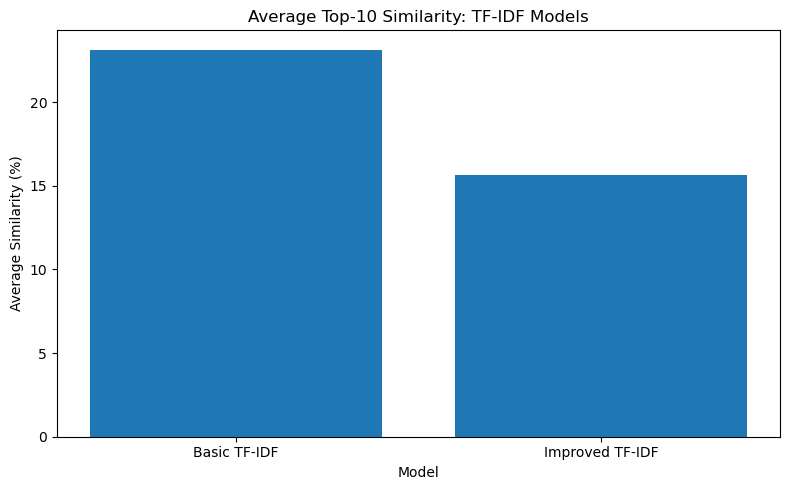

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    score_comparison["model"],
    score_comparison["average_top10_similarity"]
)

plt.title("Average Top-10 Similarity: TF-IDF Models")
plt.xlabel("Model")
plt.ylabel("Average Similarity (%)")
plt.tight_layout()
plt.show()

In [12]:
basic_rankings = pd.DataFrame({
    "filename": df.iloc[np.argsort(scores_basic)[::-1]]["filename"].values,
    "basic_rank": range(1, len(df) + 1)
})

improved_rankings = pd.DataFrame({
    "filename": df.iloc[np.argsort(scores_improved)[::-1]]["filename"].values,
    "improved_rank": range(1, len(df) + 1)
})

ranking_comparison = basic_rankings.merge(
    improved_rankings,
    on="filename"
)

ranking_comparison["rank_difference"] = (
    ranking_comparison["basic_rank"]
    - ranking_comparison["improved_rank"]
)

ranking_comparison.sort_values(
    "rank_difference",
    key=lambda column: column.abs(),
    ascending=False
).head(10)

,filename,basic_rank,improved_rank,rank_difference
1722,12786012.pdf,1723,475,1248
1702,24068423.pdf,1703,689,1014
1492,55500538.pdf,1493,536,957
107,27080812.pdf,108,1060,-952
1036,15941675.pdf,1037,116,921
1440,19072267.pdf,1441,523,918
1302,91539554.pdf,1303,389,914
1060,16103783.pdf,1061,162,899
266,10399912.pdf,267,1153,-886
1446,70750649.pdf,1447,562,885


In [13]:
model_comparison.to_csv(
    "week8_model_comparison.csv",
    index=False
)

score_comparison.to_csv(
    "week8_average_score_comparison.csv",
    index=False
)

ranking_comparison.to_csv(
    "week8_ranking_comparison.csv",
    index=False
)

print("Week 8 comparison reports saved successfully!")

Week 8 comparison reports saved successfully!


In [14]:
ml_job_description = """
We are looking for a Machine Learning Engineer with Python,
machine learning, NumPy, Pandas, and scikit-learn experience.
The candidate should develop, train, and evaluate machine learning
models and analyze data.
"""

In [15]:
ml_vector_basic = vectorizer_basic.transform([ml_job_description])
ml_vector_improved = vectorizer_improved.transform([ml_job_description])

ml_scores_basic = cosine_similarity(
    ml_vector_basic,
    resume_vectors_basic
).flatten()

ml_scores_improved = cosine_similarity(
    ml_vector_improved,
    resume_vectors_improved
).flatten()

print("Machine Learning job scores calculated successfully!")

Machine Learning job scores calculated successfully!


In [16]:
ml_basic_indices = np.argsort(ml_scores_basic)[::-1][:5]
ml_improved_indices = np.argsort(ml_scores_improved)[::-1][:5]

print("BASIC TF-IDF — MACHINE LEARNING JOB")
display(pd.DataFrame({
    "filename": df.iloc[ml_basic_indices]["filename"].values,
    "category": df.iloc[ml_basic_indices]["category"].values,
    "similarity_percentage": np.round(
        ml_scores_basic[ml_basic_indices] * 100, 2
    )
}))

print("IMPROVED TF-IDF — MACHINE LEARNING JOB")
display(pd.DataFrame({
    "filename": df.iloc[ml_improved_indices]["filename"].values,
    "category": df.iloc[ml_improved_indices]["category"].values,
    "similarity_percentage": np.round(
        ml_scores_improved[ml_improved_indices] * 100, 2
    )
}))

BASIC TF-IDF — MACHINE LEARNING JOB


,filename,category,similarity_percentage
0,12777487.pdf,ARTS,18.18
1,18835363.pdf,DESIGNER,16.73
2,12011623.pdf,ENGINEERING,16.34
3,62994611.pdf,AGRICULTURE,16.08
4,34953092.pdf,BANKING,15.09


IMPROVED TF-IDF — MACHINE LEARNING JOB


,filename,category,similarity_percentage
0,34953092.pdf,BANKING,18.90
1,12011623.pdf,ENGINEERING,17.54
2,28505854.pdf,ENGINEERING,15.75
3,22946204.pdf,AUTOMOBILE,15.58
4,12351749.pdf,SALES,13.72


In [17]:
def calculate_top10_overlap(basic_scores, improved_scores):
    basic_top = set(np.argsort(basic_scores)[::-1][:10])
    improved_top = set(np.argsort(improved_scores)[::-1][:10])

    return round(len(basic_top & improved_top) / 10 * 100, 2)

data_analyst_overlap = calculate_top10_overlap(
    scores_basic, scores_improved
)

ml_overlap = calculate_top10_overlap(
    ml_scores_basic, ml_scores_improved
)

job_overlap_summary = pd.DataFrame({
    "job_title": ["Data Analyst", "Machine Learning Engineer"],
    "top10_overlap_percentage": [
        data_analyst_overlap,
        ml_overlap
    ]
})

job_overlap_summary

,job_title,top10_overlap_percentage
0,Data Analyst,70.0
1,Machine Learning Engineer,40.0


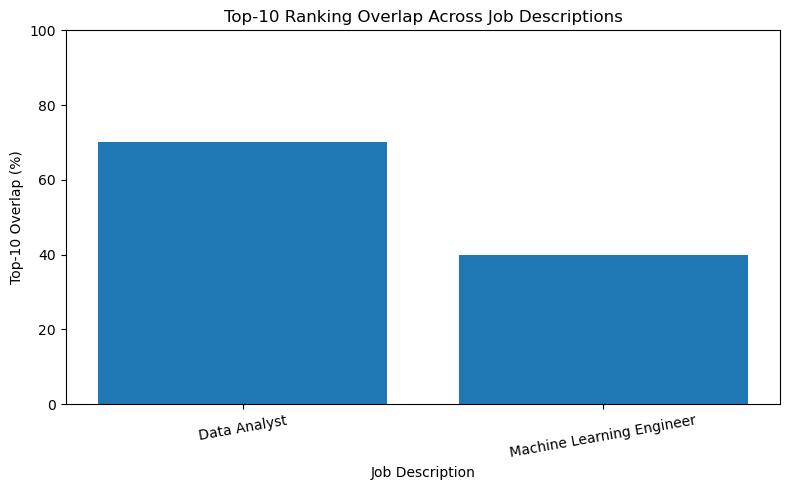

In [18]:
plt.figure(figsize=(8, 5))

plt.bar(
    job_overlap_summary["job_title"],
    job_overlap_summary["top10_overlap_percentage"]
)

plt.title("Top-10 Ranking Overlap Across Job Descriptions")
plt.xlabel("Job Description")
plt.ylabel("Top-10 Overlap (%)")
plt.ylim(0, 100)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [19]:
job_overlap_summary.to_csv(
    "week8_job_overlap_summary.csv",
    index=False
)

print("Saved: week8_job_overlap_summary.csv")

Saved: week8_job_overlap_summary.csv


In [20]:
print("=" * 55)
print("WEEK 8: MODEL COMPARISON REPORT")
print("=" * 55)

print("Usable resumes:", len(df))
print("Job descriptions tested: 2")
print("Basic model: unigrams")
print("Improved model: unigrams + bigrams with sublinear TF")

print("\nData Analyst top-10 overlap:", data_analyst_overlap, "%")
print("Machine Learning top-10 overlap:", ml_overlap, "%")

print("\nJob comparison:")
display(job_overlap_summary)

print("\nWeek 8 experiments completed!")

WEEK 8: MODEL COMPARISON REPORT
Usable resumes: 2483
Job descriptions tested: 2
Basic model: unigrams
Improved model: unigrams + bigrams with sublinear TF

Data Analyst top-10 overlap: 70.0 %
Machine Learning top-10 overlap: 40.0 %

Job comparison:


,job_title,top10_overlap_percentage
0,Data Analyst,70.0
1,Machine Learning Engineer,40.0



Week 8 experiments completed!
